# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

550.67


## Setup

In [12]:
import os

# Import LASSI modules
import lassi.llm_config
import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
%aimport lassi.pipeline
%aimport lassi.get_power
%aimport lassi.argostream_curl

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [15]:
def experimental_setup():
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["10000", "1"]
    -- jacobi [""] (none required)
    -- DNU -- mallocFree ["10000"]
    -- layout ["1"]
    -- atomicCost ["1"]
    -- dense-embedding ["10000", "8", "1"]
    -- pathfinder ["10000", "1000", "1000"]
    -- bsearch ["10000", "1"]
    -- entropy ["10000", "1024", "1"]
    -- colorwheel ["10000", "8", "1"]
    -- randomAccess ["1"]
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = "HeCBench"  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = "jacobi"  # "mandelbrot"  # "raytracing/raytracing_cuda"  # "lid-driven-cavity"   #  "bfs"
    app_name = "jacobi-cuda_main"  # "bfs"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    use_context = True  # True or False
    use_context_summaries_only = True  # True or False
    few_shot_learning = False  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_60 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = [""]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpto1preview"  # (max token = 128000)

    # -- FROM OLLAMA
    model = "granite3.2:8b-instruct-q8_0"
    model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "qwq:latest"  # (max token = 32768)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 128000
    num_ctx_coder = 128000

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "05test_ds_ee_hecb-jacobi-params"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


Unloading Ollama server...

Unload LLM:
 {"model":"granite3.2:8b-instruct-q8_0","created_at":"2025-03-07T08:46:55.246911664Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   191  100   134  100    57  44966  19127 --:--:-- --:--:-- --:--:-- 95500


Unloading Ollama server...

Unload LLM:
 {"model":"granite-code:34b-instruct-q8_0","created_at":"2025-03-07T08:46:55.254765119Z","response":"","done":true,"done_reason":"unload"}
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed

  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100   197  100   137  100    60  71577  31347 --:--:-- --:--:-- --:--:--  192k


***** 

Waiting for the system to settle down...: 100%|██████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/jacobi
Execute command: ['./jacobi-cuda_main', '']

Error after iteration 0 = 0.00276205
Error after iteration 1000 = 1.38643e-05
Average execution time per iteration: 0.00422404 (s)
PASS
Total elapsed time: 8.277 seconds
GPU power data has been written to source_CUDA_gpu_power_results.csv


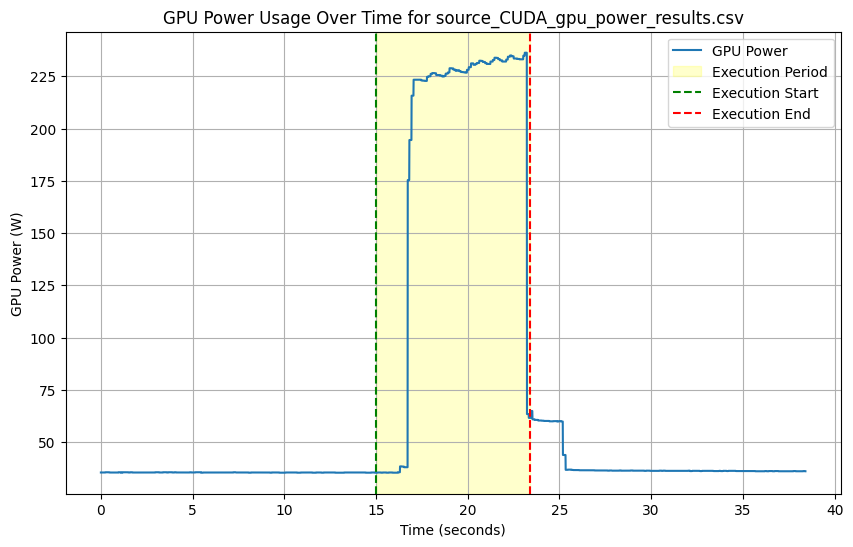

Start time: 15.015 -- End time: 23.405
Code execution duration: 8.39 seconds
Total GPU energy consumption for source_CUDA_gpu_power_results.csv:
  0.000432 kWh
  0.4316 Wh
  1553.75 J
Average GPU power: 185.19 W
Total Energy During Exe Runtime:   1553.75 J
----------------------------------------------------------------------------------------------------------------------------------------

Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 8.39
GPU power data has been written to idle__gpu_power_results.csv


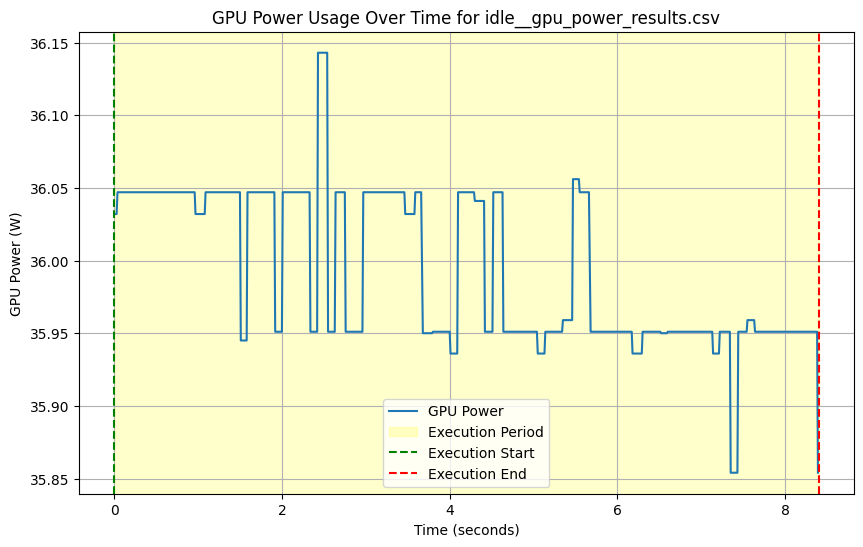

Start time: 0 -- End time: 8.399
Code execution duration: 8.40 seconds
Total GPU energy consumption for idle__gpu_power_results.csv:
  0.000084 kWh
  0.0840 Wh
  302.35 J
Average GPU power: 35.99 W
Total Energy During Exe Runtime:   302.35 J
----------------------------------------------------------------------------------------------------------------------------------------




----- STARTING LLM CONTEXT BUILDING WITH SELF-PROMPTING -----

GPU Memory Status:
 GPU 0: 637 MiB used, 40322 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

--> ... prompt LLM to summarize context knowledge.





----- CONTEXT KNOWLEDGE SUMMARY -----
 (generated by the LLM)



This text provides several performance optimization tips for CUDA programming:

1. **Minimize global memory usage**: Accessing global memory can introduce significant latency due to hundreds of clock cycles of memory latency. Prefer shared memory access where possible to reduce this latency.

   Example:
   ```
   __shared__ float shared[32];
   __device__ float device[32];
   shared[threadIdx.x] = device[threadIdx.x];
   ```

2. **Avoid warp divergence**: Flow control instructions (if, switch, do, for, while) can cause threads within the same warp to follow different execution paths, leading to reduced instruction throughput. To minimize warp divergence:

   - Write controlling conditions that align with warps. For example, if the condition depends only on `(threadIdx / WSIZE)`, no warp will diverge because the condition is perfectly aligned with the warps.
   - Use predication for branches including just a few instructions to avoid actual branching and minimize performance losses.

3. **Use branch predication**: The compiler may unroll loops or optimize out if or switch statements by using branch predication instead, which avoids warp divergence. You can also control loop unrolling using `#pragma unroll`.

   Example:
   ```
   #pragma unroll
   for (int i = 0; i < N; ++i) {
       // ...
   }
   ```

4. **Replace specific trigonometric functions with optimized versions**: Replace `sin(π*<expr>)` with `sinpi(<expr>)`, `cos(π*<expr>)` with `cospi(<expr>)`, and `sincos(π*<expr>)` with `sincospi(<expr>)`. This improves both accuracy and performance.

   Example:
   ```
   float x = ...;
   float result = sinpi(x); // instead of sin(M_PI * x)
   ```

5. **Optimize trigonometric exponentiation**: For exponentiation with specific exponents (1/3 or -1/3), use `cbrt()` or `rcbrt()` instead of generic exponentiation functions like `pow()`. These optimized functions are significantly faster for these cases.

   Example:
   ```
   float x = ...;
   float result = cbrt(x); // instead of pow(x, 1/3)
   ```

6. **Make it easy for the compiler to use branch predication**: Write code in a way that allows the compiler to unroll loops or optimize out control statements using branch predication. This can help avoid warp divergence and improve performance.

GPU Memory Status:
 GPU 0: 11345 MiB used, 29614 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total

--> ... prompt LLM to describe the source code.





----- CODE DESCRIPTION and ANALYSIS -----
 (generated by the LLM)



This is a CUDA implementation of the Jacobi iterative method for solving a system of linear equations, specifically for a 2D heat equation. Here's a breakdown of the code:

1. **Initialization**: The main function begins by allocating memory on both the host (CPU) and device (GPU) for the scalar field `f`, its "old" copy `f_old`, and an error variable `d_error`. It also initializes these arrays with data using a hypothetical `initialize_data` function.

2. **CUDA Memory Management**: The host memory is copied to device memory using `cudaMemcpy`.

3. **Error Initialization**: The error variable is initialized to a large number (`std::numeric_limits<float>::max()`) and a tolerance value (`1.e-5f`) is defined for convergence checking.

4. **Iteration Loop**: The code enters a loop that continues until the error falls below the tolerance or a maximum number of iterations (`max_iters = 10000`) is reached.

   - Within each iteration, the error is reset to zero using `cudaMemset`.
   - A Jacobi relaxation step is performed on the GPU with the `jacobi_step` kernel function. This function updates the scalar field based on its neighboring values from the previous iteration (`d_f_old`).
   - The old and new data are swapped using another kernel function, `swap_data`.
   - The error is copied back to host memory and normalized by dividing it by the total number of data points (N*N) and taking the square root.
   - Every 1000 iterations, the current error is printed out for monitoring purposes.

5. **Convergence Check**: After exiting the loop, if the error is below the tolerance and fewer than `max_iters` steps were taken, the program prints "PASS", indicating successful convergence. Otherwise, it prints "FAIL".

6. **Cleanup**: All allocated memory on both host and device is freed using `cudaFree`, and the total elapsed time for the computation is printed out.

The `jacobi_step` kernel function performs the Jacobi iteration:

- It reads neighboring values from `d_f_old`.
- Updates each value in `d_f` based on these neighbors.
- Copies updated values to a temporary array for error calculation, ensuring boundary points are handled correctly by reading from `d_f_old` instead of the updated `d_f`.

The `swap_data` kernel function simply swaps the contents of `d_f` and `d_f_old`.

This implementation demonstrates parallel computation on a GPU using CUDA, showcasing how to manage memory between host and device, launch kernels for parallel execution, and perform error checking in an iterative algorithm.

GPU Memory Status:
 GPU 0: 11332 MiB used, 29627 MiB free, 40960 MiB total
 GPU 1: 637 MiB used, 40322 MiB free, 40960 MiB total


----- REVIEW THE INSTRUCTIONS TASK PROMPT  (prompt with code, token count: 3462): 


[YOUR SUMMARY OF BACKGROUND KNOWLEDGE] This text provides several performance optimization tips for CUDA programming:

1. **Minimize global memory usage**: Accessing global memory can introduce significant latency due to hundreds of clock cycles of memory latency. Prefer shared memory access where possible to reduce this latency.

   Example:
   ```
   __shared__ float shared[32];
   __device__ float device[32];
   shared[threadIdx.x] = device[threadIdx.x];
   ```

2. **Avoid warp divergence**: Flow control instructions (if, switch, do, for, while) can cause threads within the same warp to follow different execution paths, leading to reduced instruction throughput. To minimize warp divergence:

   - Write controlling conditions that align with warps. For example, if the con



----- LLM RESPONSE -----



Summary of Identified Inefficiencies:

1. **Redundant Memory Transfers**: The code frequently transfers data between host (CPU) and device (GPU) memory, which is an energy-intensive operation. This happens in every iteration of the main loop for both `d_f` and `d_f_old`.

2. **Unnecessary Synchronization**: Although `cudaDeviceSynchronize()` is used to ensure all previous operations are completed before measuring time, it might not be necessary after each kernel launch if the GPU can handle overlapping computation and memory transfers.

3. **Fixed Grid and Block Sizes**: The grid and block sizes are fixed (`N/16` and `16`, respectively), which may not always be optimal for the problem size or GPU architecture, potentially leading to underutilization of resources.

4. **Error Calculation Overhead**: The error is calculated in every iteration, even though it might converge quickly. This frequent calculation adds unnecessary computational overhead.

5. **Lack of Coalesced Memory Access**: While not explicitly visible from the provided code snippet, ensuring coalesced memory access patterns can significantly improve GPU performance and energy efficiency.

6. **No Use of Shared Memory**: The kernels do not appear to utilize shared memory, which could be beneficial for reducing global memory accesses and improving performance on GPUs.

7. **Thread Divergence**: Although not evident from the provided code, thread divergence (when threads within a warp follow different execution paths) can lead to inefficiencies and should be minimized.

Refactoring Plan for Energy Efficiency:

1. **Reduce Memory Transfers**:
   - Minimize the frequency of data transfers between host and device memory. Instead of swapping `d_f` and `d_f_old` explicitly, consider using a double-buffering approach where one buffer is updated while the other is read by the next iteration's kernel launch.

2. **Optimize Synchronization**:
   - Use asynchronous operations where possible to overlap computation with memory transfers. For instance, launch kernels asynchronously and use `cudaStreamWaitEvent()` or similar mechanisms to ensure correct execution order without blocking the CPU.

3. **Dynamic Grid and Block Sizes**:
   - Implement a mechanism to dynamically adjust grid and block sizes based on the problem size and GPU capabilities. This can help in better utilizing GPU resources and potentially reducing energy consumption by avoiding overprovisioning or underutilization.

4. **Efficient Error Calculation**:
   - Instead of calculating error in every iteration, consider doing so at predefined intervals (e.g., every 10 iterations) or when a certain convergence criterion is met. This reduces the computational overhead associated with error calculation.

5. **Coalesced Memory Access**:
   - Ensure that memory access patterns within the kernels are coalesced to maximize memory throughput and reduce energy consumption due to inefficient memory transactions.

6. **Utilize Shared Memory**:
   - Modify the kernels to make use of shared memory for frequently accessed data, reducing global memory accesses and potentially improving performance and energy efficiency.

7. **Minimize Thread Divergence**:
   - Analyze and refactor the kernel logic to minimize thread divergence. This might involve restructuring loops or conditional statements to ensure threads within a warp follow similar execution paths as much as possible.

8. **Profiling and Tuning**:
   - Employ GPU profiling tools (like NVIDIA's Nsight or nvprof) to identify bottlenecks and further optimize the code based on actual performance metrics rather than assumptions.

9. **Energy-Aware Scheduling**:
   - If the system supports it, consider using energy-aware scheduling policies that can dynamically adjust the power state of the GPU based on workload demands, potentially reducing overall energy consumption without sacrificing performance.

By implementing these optimizations, the code could see improvements in both performance and energy efficiency, although the exact impact would need to be validated through profiling and testing.



----- REVIEW THE REFACTORING PLAN PROMPT  (prompt with code, token count: 4265): 

[Goal] Following the refactoring plan for the SOURCE CODE below, refactor the code to improve energy efficiency without altering its original functionality, outputs, or performance if possible. [Key Requirements] Maintain Function Signatures & Kernel Logic: Keep all existing function and kernel names, parameters, and return types. Ensure Compilability: The refactored code must compile with NVCC as before. Energy Efficiency: Introduce modifications aimed at reducing power consumption (for example, improved memory access, streamlined concurrency, shared memory utilization, etc.). Concise Comments for Rationale: Place only brief inline comments to explain each energy‐related refactoring choice. Avoid describing the entire code flow. Do Not Repeat the Plan or Give Explanations Outside the Code: Only provide the updated source code. [Return Format] Output Only the Refactored Source Code wrapped in triple ba

KeyboardInterrupt: 

In [16]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))


# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n\n" + color.BOLD + "***** BEGIN THE LASSI PIPELINE*****" + color.END + "\n\n")

# RUN PIPELINE
complete = lassi.pipeline.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure, 
    test_code_first,
    yes_power_feedback
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)